# Annual Returns vs. Benchmark

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Paired columns showing a fund's and its benchmark's return for each calendar year, with a lower panel of the yearly difference (excess return). Calendar-year returns are what regulators and factsheets report, and the pairing shows at once in which years the fund helped or hurt.

## When to use

- Report calendar-year performance against a benchmark
- Show whether out- or under-performance is consistent or driven by a few years
- Complement a cumulative-return chart, which hides year-to-year variation

## Avoid when

- More than about 15 years (switch to a line of rolling returns)
- More than two or three series (bars become a picket fence; use a heatmap)

## Alternatives

- Monthly returns heatmap
- Rolling 12-month return line
- Dumbbell chart (fund vs benchmark per year)

## Design tips

- Keep the benchmark recessive (gray) and the fund in the primary color
- Show the excess return in its own panel instead of asking readers to subtract bars
- Start the y-axis at zero; bars must have a zero baseline

## Example

Simulated calendar-year returns of a fund and its benchmark, 2015–2024. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.ticker import PercentFormatter

### Data

In [2]:
rng = np.random.default_rng(21)
dates = pd.bdate_range("2015-01-01", "2024-12-31")
n = len(dates)
mkt = 0.00045 + rng.standard_t(4, n) * 0.0095 / np.sqrt(2)
mkt[(dates >= "2020-02-20") & (dates <= "2020-03-23")] -= 0.012
mkt[(dates >= "2022-01-01") & (dates <= "2022-10-15")] -= 0.0011
fund = 0.00024 + 0.9 * mkt + rng.normal(0, 0.004, n)
daily = pd.DataFrame({"Fund": fund, "Benchmark": mkt}, index=dates)
annual = (1 + daily).groupby(daily.index.year).prod() - 1
annual

,Fund,Benchmark
2015,0.394672,0.241012
2016,-0.025075,-0.024590
2017,0.370157,0.481057
2018,0.046164,0.138323
2019,0.149235,0.053158
2020,-0.199929,-0.166863
2021,0.208547,0.160821
2022,-0.052189,-0.139036
2023,0.194185,0.244397
2024,0.200569,0.131738


### Plot

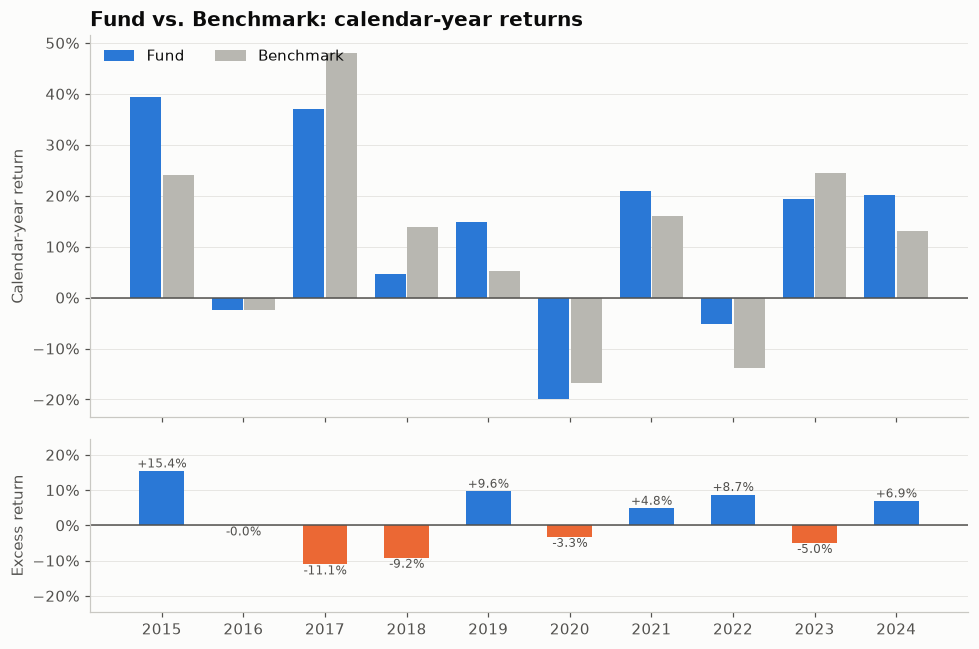

In [3]:
fund_name, bench_name = annual.columns[:2]
x = np.arange(len(annual))
excess = annual[fund_name] - annual[bench_name]
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax.bar(x - 0.2, annual[fund_name], width=0.38, color=PALETTE[0], label=fund_name)
ax.bar(x + 0.2, annual[bench_name], width=0.38, color=GRAY, label=bench_name)
ax.axhline(0, color="#52514e", linewidth=1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylabel("Calendar-year return")
ax.set_title(f"{fund_name} vs. {bench_name}: calendar-year returns")
ax.legend(loc="upper left", ncol=2)
ax.grid(axis="x", visible=False)

colors = np.where(excess >= 0, PALETTE[0], PALETTE[1])
ax2.bar(x, excess, width=0.55, color=colors)
ax2.axhline(0, color="#52514e", linewidth=1)
for xi, v in zip(x, excess):
    ax2.text(xi, v + (0.002 if v >= 0 else -0.002), f"{v:+.1%}", ha="center",
             va="bottom" if v >= 0 else "top", fontsize=8, color="#52514e")
ax2.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax2.set_ylabel("Excess return")
lim = np.abs(excess).max() * 1.6
ax2.set_ylim(-lim, lim)
ax2.set_xticks(x, annual.index)
ax2.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

## How to read it

In the top panel each pair of bars is one year: blue is the fund, gray the benchmark. The bottom panel shows the difference: blue bars are years the fund beat the benchmark, orange bars years it lagged.

---
Standalone script: [`annual_returns_bar.py`](annual_returns_bar.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)